Training device is cuda:0.


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 200kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.79MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 27.5MB/s]


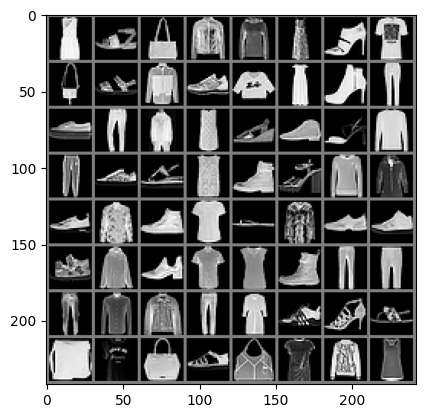

Categories for the first row:
Dress, Sandal, Bag, Coat, Pullover, Dress, Ankle boot, T-shirt/top


In [ ]:

import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

# Determine the training device
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(f"Training device is {device}.")
# Data Preparation

transform = transforms.Compose([
    transforms.ToTensor(),	# Converts a PIL Image or numpy.ndarray to a tensor.
    transforms.Normalize((0.5,), (0.5,))	#  Normalizes a tensor with mean and standard deviation.
])

torch.manual_seed(1024) # Fix random seed

# Downloads the Fashion-MNIST dataset.
trainset = torchvision.datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
# Provides an iterable over the given dataset.
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

testset = torchvision.datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=False)
# Let us print some samples in the dataset
import matplotlib.pyplot as plt
import numpy as np

# Function to show an image
def imshow(img):
    img = img / 2 + 0.5  # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

# Get some random training images
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Show images
imshow(torchvision.utils.make_grid(images))

# Print labels
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
print('Categories for the first row:')
print(', '.join(f'{classes[labels[j]]}' for j in range(8)))

In [ ]:
# Edited Code

import torch
import torchvision
import torchvision.transforms as transforms
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import time

device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')

# Data preparation
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

torch.manual_seed(1024)

trainset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.FashionMNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

# Defining the model
class SimpleCNN(nn.Module):
    def __init__(self, size='medium'):
        super().__init__()

        if size == 'small':
            c1, c2, fc = 16, 32, 64
        elif size == 'medium':
            c1, c2, fc = 32, 64, 128
        else:  # large
            c1, c2, fc = 64, 128, 256

        self.conv1 = nn.Conv2d(1, c1, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.conv2 = nn.Conv2d(c1, c2, kernel_size=3, padding=1)

        self.fc1 = nn.Linear(c2 * 7 * 7, fc)
        self.fc2 = nn.Linear(fc, 10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))

        x = torch.flatten(x, 1)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x

# Run one experiment
def run_experiment(size='medium', lr=0.001):

    print(f"\n===== Size = {size}, Learning Rate = {lr} =====")

    net = SimpleCNN(size).to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(
        net.parameters(),
        lr=lr,
        momentum=0.9
    )

    for epoch in range(10):

        # Training
        net.train()

        train_start = time.time()

        train_loss = 0.0
        train_correct = 0
        train_total = 0

        for inputs, labels in trainloader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = net(inputs)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            train_correct += (predicted == labels).sum().item()
            train_total += labels.size(0)

        train_time = time.time() - train_start

        # Validation
        net.eval()

        val_start = time.time()

        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in testloader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = net(images)

                loss = criterion(outputs, labels)

                val_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)

        val_time = time.time() - val_start

        print(
            f"Epoch {epoch + 1}: "
            f"Train Time = {train_time:.1f}s, "
            f"Val Time = {val_time:.1f}s | "
            f"Train Loss = {train_loss / len(trainloader):.3f}, "
            f"Val Loss = {val_loss / len(testloader):.3f} | "
            f"Train Acc = {100 * train_correct / train_total:.2f}%, "
            f"Val Acc = {100 * val_correct / val_total:.2f}%"
        )

    print(f"Final Validation Accuracy: {100 * val_correct / val_total:.2f}%")

# Run all experiments
experiments = [
    ('medium', 0.01),
    ('medium', 0.001),
    ('medium', 0.0001),
    ('small', 0.001),
    ('large', 0.001)
]

for size, lr in experiments:
    run_experiment(size, lr)


===== Size = medium, Learning Rate = 0.01 =====
Epoch 1: Train Time = 14.6s, Val Time = 3.2s | Train Loss = 0.532, Val Loss = 0.379 | Train Acc = 80.77%, Val Acc = 85.97%
Epoch 2: Train Time = 15.6s, Val Time = 2.1s | Train Loss = 0.315, Val Loss = 0.311 | Train Acc = 88.54%, Val Acc = 88.89%
Epoch 3: Train Time = 15.5s, Val Time = 2.4s | Train Loss = 0.270, Val Loss = 0.291 | Train Acc = 90.11%, Val Acc = 89.47%
Epoch 4: Train Time = 16.2s, Val Time = 2.6s | Train Loss = 0.238, Val Loss = 0.276 | Train Acc = 91.20%, Val Acc = 90.18%
Epoch 5: Train Time = 15.4s, Val Time = 2.5s | Train Loss = 0.217, Val Loss = 0.252 | Train Acc = 92.02%, Val Acc = 91.05%
Epoch 6: Train Time = 14.2s, Val Time = 1.9s | Train Loss = 0.196, Val Loss = 0.258 | Train Acc = 92.77%, Val Acc = 90.62%
Epoch 7: Train Time = 14.4s, Val Time = 1.9s | Train Loss = 0.180, Val Loss = 0.247 | Train Acc = 93.39%, Val Acc = 90.97%
Epoch 8: Train Time = 14.7s, Val Time = 2.4s | Train Loss = 0.165, Val Loss = 0.242 | Trai